In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('Social_Network_Ads.csv')

In [3]:
df.head(2)

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0


In [4]:
df.drop(columns = ['User ID', 'Gender'], inplace = True)

In [5]:
df.head(2)

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0


In [6]:
X=df.iloc[:,0:2].values

In [7]:
X.shape

(400, 2)

In [8]:
y=df.iloc[:,-1].values

In [9]:
from sklearn.model_selection import train_test_split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2)

In [11]:
X_train.shape

(320, 2)

In [12]:
X_test.shape

(80, 2)

In [13]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [14]:
X_train = scaler.fit_transform(X_train)

In [15]:
X_train

array([[ 0.05339932,  0.01528655],
       [-0.91749735,  0.2539059 ],
       [ 0.24757865,  0.13459623],
       [ 0.83011665,  0.34338816],
       [ 0.44175798, -0.16367796],
       [-0.91749735, -0.34264247],
       [ 0.44175798,  0.28373332],
       [-1.20876635,  0.49252525],
       [-1.20876635,  0.5820075 ],
       [-0.62622835,  0.01528655],
       [-0.91749735,  0.40304299],
       [ 0.92720632, -1.50591179],
       [ 0.05339932,  0.01528655],
       [-0.23786968, -1.50591179],
       [-0.52913868, -1.56556663],
       [-0.62622835,  0.16442364],
       [ 0.05339932,  1.26803813],
       [ 0.44175798,  0.28373332],
       [-0.52913868,  2.37165261],
       [-1.01458702, -1.17781019],
       [-0.23786968, -1.29711986],
       [-0.62622835, -1.08832793],
       [ 1.80101331,  1.8645865 ],
       [ 0.05339932, -0.28298763],
       [ 1.60683398,  0.99959136],
       [-0.04369035,  0.2539059 ],
       [ 0.83011665,  1.3873478 ],
       [-0.91749735, -0.99884568],
       [-1.40294568,

In [16]:
X_test = scaler.transform(X_test)

In [17]:
X_test

array([[ 1.21847532, -0.79005375],
       [ 2.09228231, -1.23746502],
       [-1.30585602, -1.14798277],
       [-0.72331802,  1.35752038],
       [-0.23786968,  0.01528655],
       [ 1.50974432,  0.34338816],
       [ 0.44175798, -0.49177956],
       [-0.43204902, -0.879536  ],
       [-1.59712502, -0.0741957 ],
       [-0.72331802, -1.59539404],
       [-1.69421468,  0.34338816],
       [ 1.89810298, -1.11815535],
       [ 2.18937198, -0.84970858],
       [-0.91749735, -0.46195214],
       [-0.52913868,  1.3873478 ],
       [-0.72331802,  0.55218008],
       [ 1.31556498,  2.25234294],
       [ 0.24757865, -0.40229731],
       [ 0.63593732,  2.04355101],
       [ 0.24757865,  1.08907362],
       [-0.43204902, -0.58126182],
       [ 1.02429598, -1.2076376 ],
       [-0.23786968, -0.31281505],
       [-1.88839401,  0.46269783],
       [ 1.41265465, -0.96901826],
       [ 1.02429598,  2.01372359],
       [-0.62622835, -0.37246989],
       [ 0.05339932, -0.61108924],
       [-1.01458702,

In [18]:
# Finding the value of K

In [19]:
K=int(np.sqrt(X_train.shape[0]))

In [20]:
K

17

In [21]:
from sklearn.neighbors import KNeighborsClassifier
Knn = KNeighborsClassifier(n_neighbors=K)

In [22]:
Knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=17)

In [23]:
y_pred = Knn.predict(X_test)

In [24]:
y_pred.shape

(80,)

In [25]:
from sklearn.metrics import accuracy_score

In [26]:
accuracy_score(y_test, y_pred)*100

91.25

In [27]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test, y_pred)

array([[42,  5],
       [ 2, 31]], dtype=int64)

In [28]:
accuracy = []
for i in range(1,26):
    knn=KNeighborsClassifier(n_neighbors=i)
    knn.fit(X_train, y_train)
    accuracy.append(accuracy_score(y_test, knn.predict(X_test)))

In [29]:
len(accuracy)

25

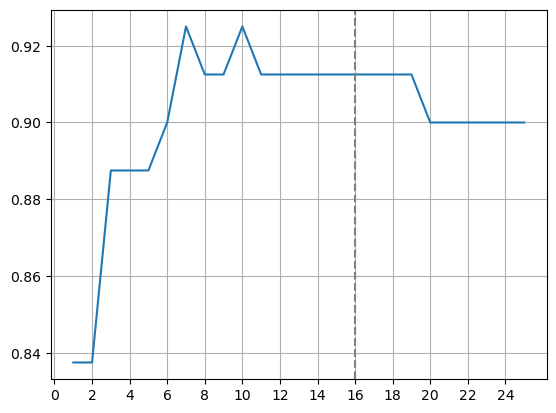

In [30]:
plt.plot(range(1,26), accuracy)
plt.axvline(x=16, color='gray', linestyle='--') 
plt.xticks([0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24])
plt.grid()

In [31]:
knn=KNeighborsClassifier(n_neighbors=19)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

In [32]:
accuracy_score(y_test, y_pred)*100

91.25

In [33]:
knn=KNeighborsClassifier(n_neighbors=16)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

In [34]:
accuracy_score(y_test, y_pred)*100

91.25

In [35]:
def predict_output():
    age = int(input("Enter your age :"))
    salary = int(input("Enter your Salary : "))
    print(np.array([[age], [salary]]))
    X_new = np.array([[age], [salary]]).reshape(1,2)
    X_new =scaler.transform(X_new)
    if knn.predict(X_new)[0]==0:
        return "Will not purchase"
    else:
        return "Will purchase"


In [36]:
predict_output()

Enter your age :55
Enter your Salary : 55
[[55]
 [55]]


'Will purchase'

In [37]:
y_pred.shape

(80,)

In [38]:
y_test.shape

(80,)

In [39]:
from sklearn.metrics import accuracy_score, confusion_matrix

In [41]:
accuracy_score(y_test, y_pred)*100

91.25

In [42]:
confusion_matrix(y_test, y_pred)

array([[42,  5],
       [ 2, 31]], dtype=int64)

In [43]:
# Training  

In [44]:
error_train = []
error_test = []

for i in range(1,26):
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(X_train,y_train)
    x = confusion_matrix(y_train, knn.predict(X_train))
    y = confusion_matrix(y_test, knn.predict(X_test))
    error_train.append(x[0][1]+x[1][0]/x.sum())
    error_test.append((y[0][1]+y[1][0])/y.sum())

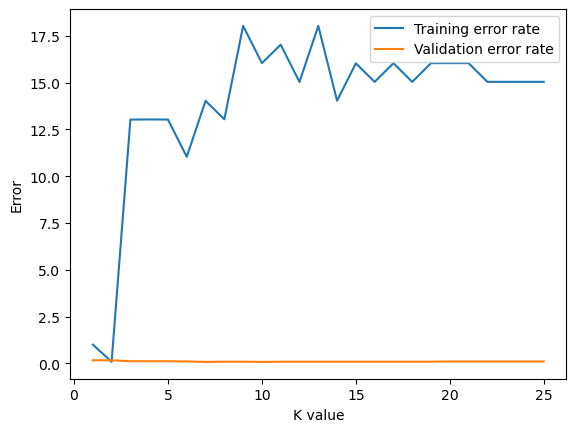

In [45]:
plt.plot(range(1,26), error_train, label='Training error rate')
plt.plot(range(1,26), error_test, label='Validation error rate')
plt.xlabel("K value")
plt.ylabel('Error')
plt.legend()